# Student Performance Analysis

Using Python, Pandas, Seaborn, Matplotlib, and Scikit-learn to explore the variables.

## Dataset
Dataset obtained from Kaggle.

#### Project by Miguel Estrada


In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
#Importing the data
students_performance = pd.read_csv('StudentPerformanceFactors.csv')
students_performance.head(4)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71


In [38]:
students_performance.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [39]:
students_performance.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [40]:
students_performance.dropna(inplace=True)

In [41]:
students_performance.isna().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [42]:
students_performance.info()

<class 'pandas.DataFrame'>
Index: 6378 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6378 non-null   int64
 1   Attendance                  6378 non-null   int64
 2   Parental_Involvement        6378 non-null   str  
 3   Access_to_Resources         6378 non-null   str  
 4   Extracurricular_Activities  6378 non-null   str  
 5   Sleep_Hours                 6378 non-null   int64
 6   Previous_Scores             6378 non-null   int64
 7   Motivation_Level            6378 non-null   str  
 8   Internet_Access             6378 non-null   str  
 9   Tutoring_Sessions           6378 non-null   int64
 10  Family_Income               6378 non-null   str  
 11  Teacher_Quality             6378 non-null   str  
 12  School_Type                 6378 non-null   str  
 13  Peer_Influence              6378 non-null   str  
 14  Physical_Activity       

### Graphical analysis

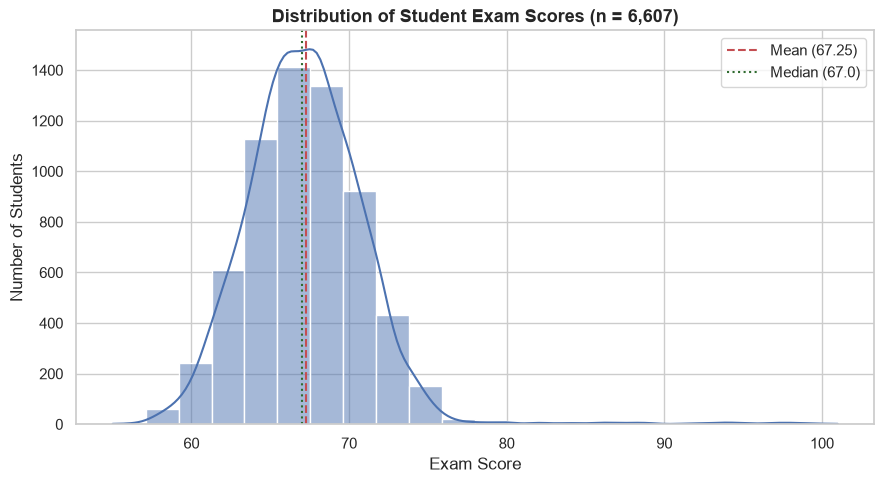

In [55]:
sns.set_theme(style="whitegrid", palette="muted")

plt.figure(figsize=(9, 5))
sns.histplot(data=students_performance, x="Exam_Score", bins=22, kde=True, color="#4C72B0")
plt.axvline(
    students_performance["Exam_Score"].mean(),
    color="#C44E52",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean ({students_performance['Exam_Score'].mean():.2f})",
)
plt.axvline(
    students_performance["Exam_Score"].median(),
    color="#2F6B2F",
    linestyle=":",
    linewidth=1.5,
    label=f"Median ({students_performance['Exam_Score'].median():.1f})",
)
plt.title(
    "Distribution of Student Exam Scores (n = 6,607)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.show()

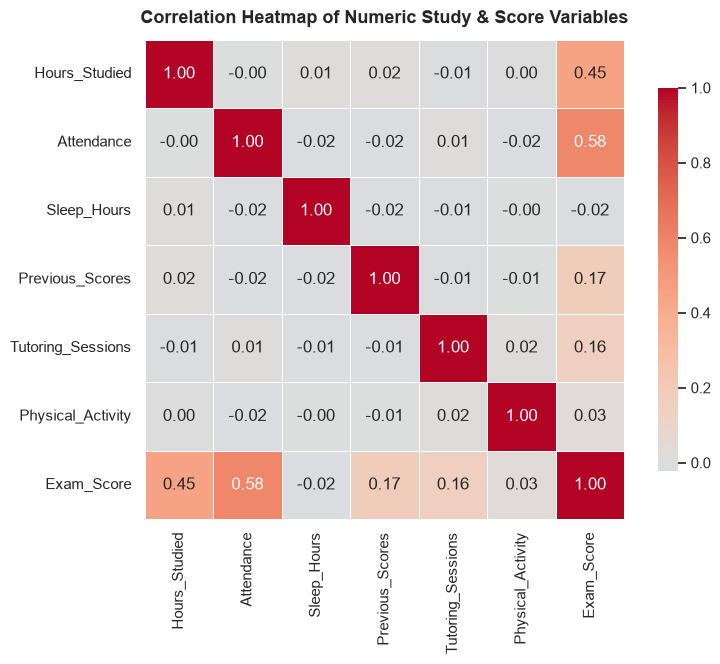

In [56]:
# Cell 2: Correlation Heatmap of Numeric Columns
plt.figure(figsize=(8.5, 6.8))
sns.heatmap(
    students_performance.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "Correlation Heatmap of Numeric Study & Score Variables",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

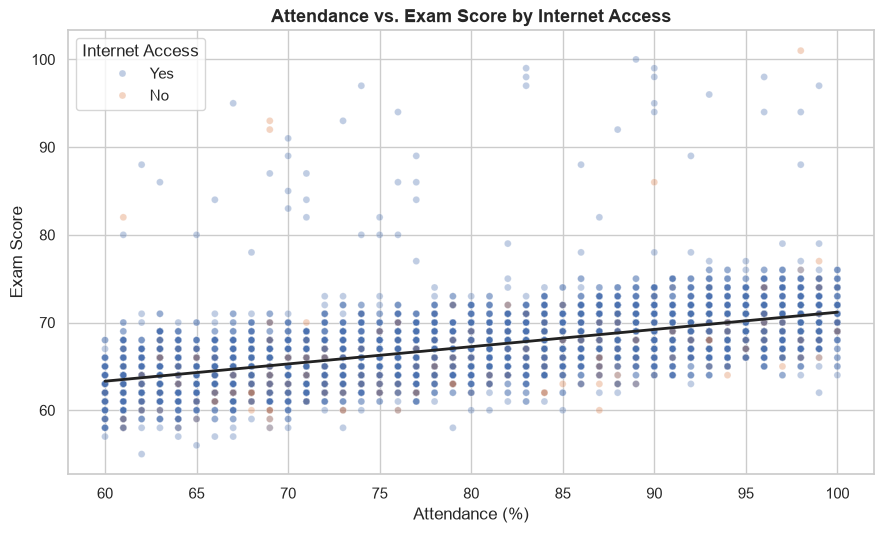

In [57]:
# Cell 3: Scatterplot + Overall Regression Trendline
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=students_performance,
    x="Attendance",
    y="Exam_Score",
    hue="Internet_Access",
    alpha=0.35,
    s=25,
    palette={"Yes": "#4C72B0", "No": "#DD8452"},
)
sns.regplot(
    data=students_performance,
    x="Attendance",
    y="Exam_Score",
    scatter=False,
    color="#222222",
    line_kws={"linewidth": 2, "label": "Overall Trend"},
)
plt.title(
    "Attendance vs. Exam Score by Internet Access",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.legend(title="Internet Access")
plt.tight_layout()
plt.show()

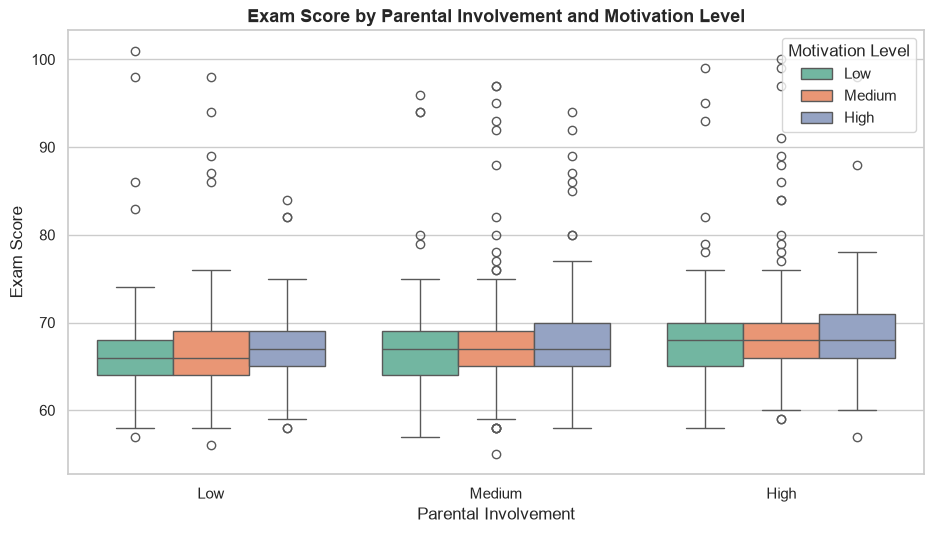

In [58]:
# Cell 4: Grouped Boxplot across Two Ordinal Categories
order_3 = ["Low", "Medium", "High"]

plt.figure(figsize=(9.5, 5.5))
sns.boxplot(
    data=students_performance,
    x="Parental_Involvement",
    y="Exam_Score",
    hue="Motivation_Level",
    order=order_3,
    hue_order=order_3,
    palette="Set2",
)
plt.title(
    "Exam Score by Parental Involvement and Motivation Level",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Parental Involvement")
plt.ylabel("Exam Score")
plt.legend(title="Motivation Level")
plt.tight_layout()
plt.show()

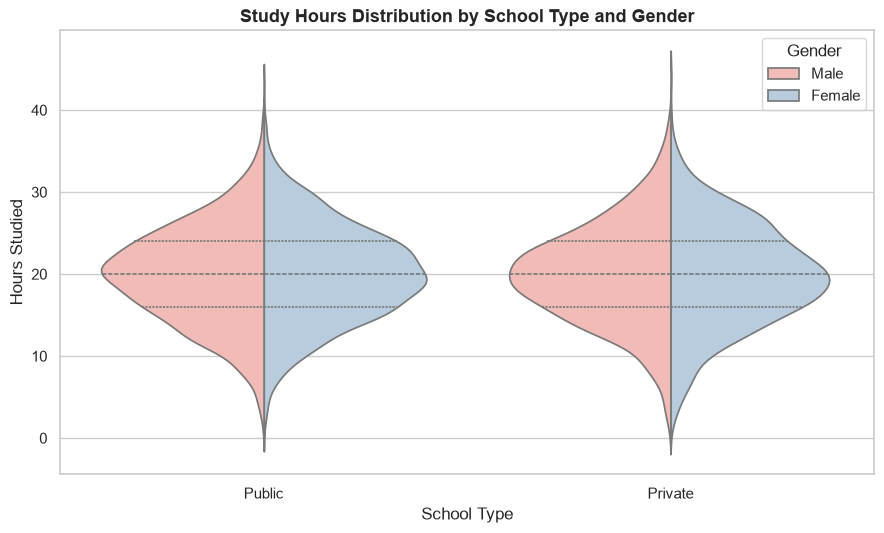

In [59]:
# Cell 5: Split Violin Plot for Study Hours
plt.figure(figsize=(9, 5.5))
sns.violinplot(
    data=students_performance,
    x="School_Type",
    y="Hours_Studied",
    hue="Gender",
    split=True,
    inner="quartile",
    palette="Pastel1",
)
plt.title(
    "Study Hours Distribution by School Type and Gender",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("School Type")
plt.ylabel("Hours Studied")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

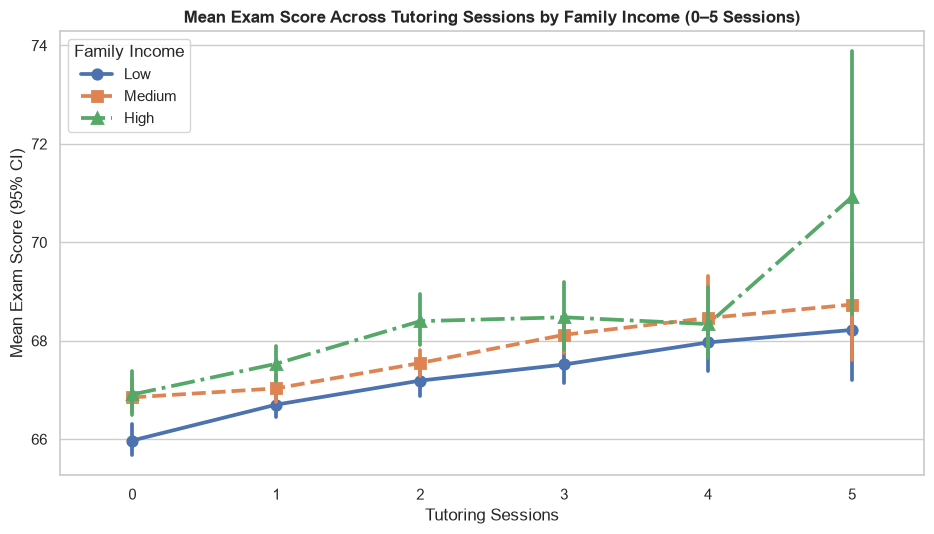

In [60]:
# Cell 6: Point Plot with 95% Confidence Intervals
tutor_sub = students_performance[students_performance["Tutoring_Sessions"] <= 5]

plt.figure(figsize=(9.5, 5.5))
sns.pointplot(
    data=tutor_sub,
    x="Tutoring_Sessions",
    y="Exam_Score",
    hue="Family_Income",
    hue_order=order_3,
    markers=["o", "s", "^"],
    linestyles=["-", "--", "-."],
    palette="deep",
)
plt.title(
    "Mean Exam Score Across Tutoring Sessions by Family Income (0–5 Sessions)",
    fontsize=12.5,
    fontweight="bold",
)
plt.xlabel("Tutoring Sessions")
plt.ylabel("Mean Exam Score (95% CI)")
plt.legend(title="Family Income")
plt.tight_layout()
plt.show()

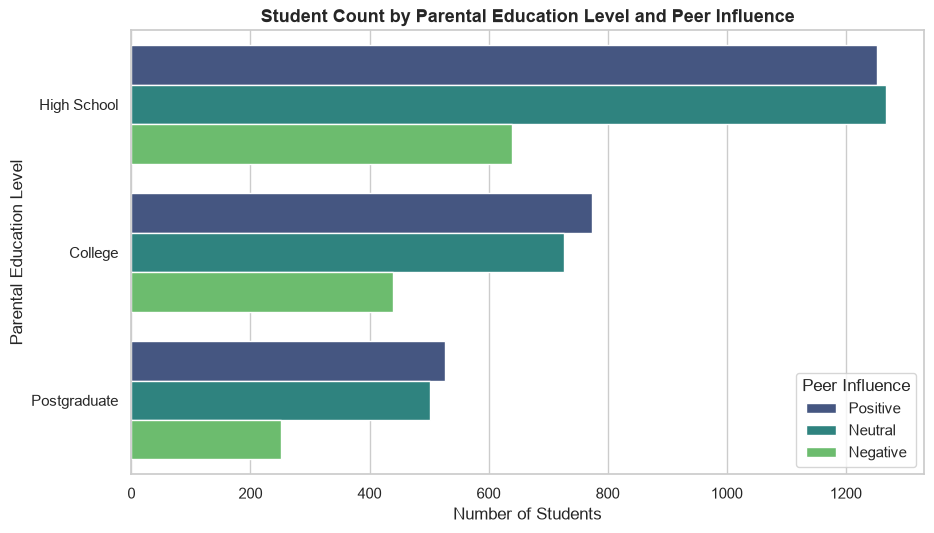

In [61]:
# Cell 7: Horizontal Grouped Countplot
edu_order = ["High School", "College", "Postgraduate"]

plt.figure(figsize=(9.5, 5.5))
sns.countplot(
    data=students_performance,
    y="Parental_Education_Level",
    hue="Peer_Influence",
    order=edu_order,
    hue_order=["Positive", "Neutral", "Negative"],
    palette="viridis",
)
plt.title(
    "Student Count by Parental Education Level and Peer Influence",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Number of Students")
plt.ylabel("Parental Education Level")
plt.legend(title="Peer Influence")
plt.tight_layout()
plt.show()

In [43]:
# Separate the target from the input variables
X = students_performance.drop(columns="Exam_Score").copy()
y = students_performance["Exam_Score"].copy()

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Target: charges")

Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']
Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Target: charges


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_24076\757304157.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


### Split the data and prepare the preprocessing steps

We split the data before fitting the preprocessing steps to avoid data leakage. The `OneHotEncoder` learns category values from the training set and can safely handle unseen categories in the test set.

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numerical_features)
    ],
    remainder="drop"
)

print("Training rows:", len(x_train))
print("Testing rows:", len(x_test))


Training rows: 5102
Testing rows: 1276


### Train the XGBoost regression model

The model keeps the same general approach as the original notebook (XGBoost regression), with reproducible settings and less extreme tree depth to help limit overfitting.

In [45]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        objective="reg:squarederror",
        learning_rate=0.05,
        max_depth=4,
        n_estimators=500,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(x_train, y_train)
print("Model training completed.")


Model training completed.


In [46]:
# Predict insurance charges on the test set
y_predict = model.predict(x_test)

# Evaluate regression performance
rmse = np.sqrt(mean_squared_error(y_test, y_predict))
mse = mean_squared_error(y_test, y_predict)
mae = mean_absolute_error(y_test, y_predict)
r2 = r2_score(y_test, y_predict)

print(f"RMSE = {rmse:.3f}")
print(f"MSE  = {mse:.3f}")
print(f"MAE  = {mae:.3f}")
print(f"R²   = {r2:.4f}")


RMSE = 2.152
MSE  = 4.632
MAE  = 0.725
R²   = 0.7019


## 1. Permutation feature importance

Permutation importance evaluates each original column directly. A larger positive value means that shuffling that column caused a larger decrease in the model's test-set performance.

We use negative root mean squared error (`neg_root_mean_squared_error`) as the scoring metric. This makes the importance values interpretable as the increase in prediction error caused by shuffling a feature.

In [47]:
permutation_result = permutation_importance(
    model,
    x_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": permutation_result.importances_mean,
    "importance_std": permutation_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(permutation_importance_df)


,feature,importance_mean,importance_std
1,Attendance,1.718120,0.040279
0,Hours_Studied,1.112258,0.040937
2,Parental_Involvement,0.209833,0.022774
3,Access_to_Resources,0.207553,0.015052
6,Previous_Scores,0.189503,0.024995
9,Tutoring_Sessions,0.171647,0.017008
13,Peer_Influence,0.071392,0.010617
16,Parental_Education_Level,0.066603,0.013222
10,Family_Income,0.048969,0.012399
7,Motivation_Level,0.045229,0.009872


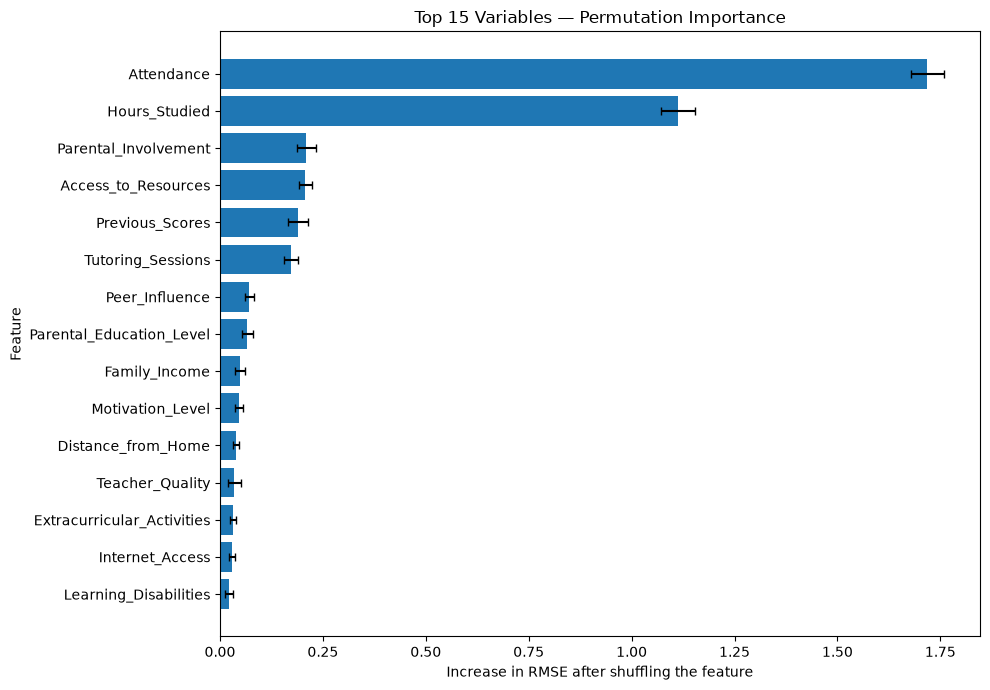

In [48]:
# Plot permutation importance for the 15 most important original columns
top_permutation = permutation_importance_df.head(15).sort_values("importance_mean")

plt.figure(figsize=(10, 7))
plt.barh(
    top_permutation["feature"],
    top_permutation["importance_mean"],
    xerr=top_permutation["importance_std"],
    capsize=3
)
plt.xlabel("Increase in RMSE after shuffling the feature")
plt.ylabel("Feature")
plt.title("Top 15 Variables — Permutation Importance")
plt.tight_layout()
plt.show()


## 2. XGBoost feature importance

XGBoost calculates importance for the features it receives after preprocessing. Since one-hot encoding can turn one original categorical column into several encoded columns, we aggregate those encoded importance values back into their original column.

This gives us a second ranking that can be compared with permutation importance.

In [49]:
# Retrieve the trained XGBoost model and encoded feature names
trained_regressor = model.named_steps["regressor"]
encoded_feature_names = model.named_steps["preprocessor"].get_feature_names_out()
encoded_importances = trained_regressor.feature_importances_

encoded_importance_df = pd.DataFrame({
    "encoded_feature": encoded_feature_names,
    "importance": encoded_importances
})

def get_original_feature(encoded_name):
    # Remove the ColumnTransformer prefix, such as "categorical__" or "numerical__"
    feature_name = encoded_name.split("__", 1)[1]

    # Map one-hot encoded columns back to their original categorical column
    for column in categorical_features:
        if feature_name == column or feature_name.startswith(column + "_"):
            return column

    # Numerical columns remain as a single feature
    for column in numerical_features:
        if feature_name == column:
            return column

    return feature_name

encoded_importance_df["feature"] = encoded_importance_df["encoded_feature"].apply(
    get_original_feature
)

xgboost_importance_df = (
    encoded_importance_df.groupby("feature", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

display(xgboost_importance_df)


,feature,importance
1,Attendance,0.142136
0,Access_to_Resources,0.115298
11,Parental_Involvement,0.095319
6,Hours_Studied,0.075798
4,Family_Income,0.068692
12,Peer_Influence,0.065362
2,Distance_from_Home,0.060289
9,Motivation_Level,0.058814
10,Parental_Education_Level,0.054871
17,Teacher_Quality,0.046957


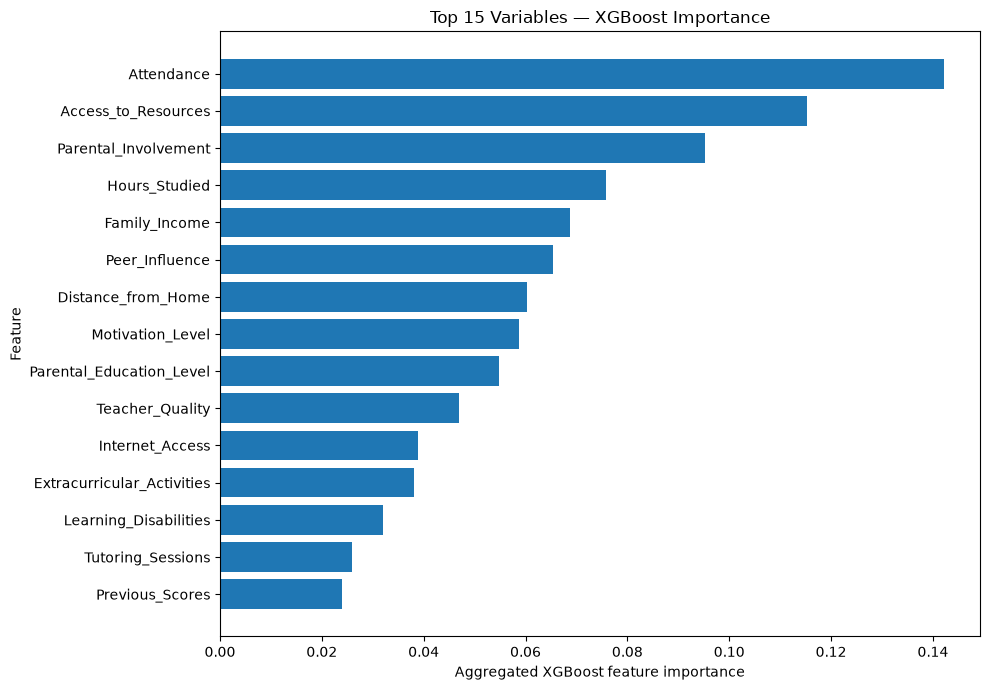

In [50]:
# Plot XGBoost importance aggregated by original column
top_xgboost = xgboost_importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_xgboost["feature"], top_xgboost["importance"])
plt.xlabel("Aggregated XGBoost feature importance")
plt.ylabel("Feature")
plt.title("Top 15 Variables — XGBoost Importance")
plt.tight_layout()
plt.show()


## 3. Compare both feature-importance methods

Permutation importance measures the effect of a feature on held-out prediction performance. XGBoost importance describes how the fitted trees used the encoded features. The rankings may differ, so comparing both provides a more balanced view.

In [51]:
importance_comparison = (
    permutation_importance_df[["feature", "importance_mean"]]
    .merge(
        xgboost_importance_df,
        on="feature",
        how="outer"
    )
    .fillna(0)
    .rename(columns={
        "importance_mean": "permutation_importance",
        "importance": "xgboost_importance"
    })
    .sort_values("permutation_importance", ascending=False)
)

display(importance_comparison)


,feature,permutation_importance,xgboost_importance
1,Attendance,1.718120,0.142136
6,Hours_Studied,1.112258,0.075798
11,Parental_Involvement,0.209833,0.095319
0,Access_to_Resources,0.207553,0.115298
14,Previous_Scores,0.189503,0.023870
18,Tutoring_Sessions,0.171647,0.025878
12,Peer_Influence,0.071392,0.065362
10,Parental_Education_Level,0.066603,0.054871
4,Family_Income,0.048969,0.068692
9,Motivation_Level,0.045229,0.058814


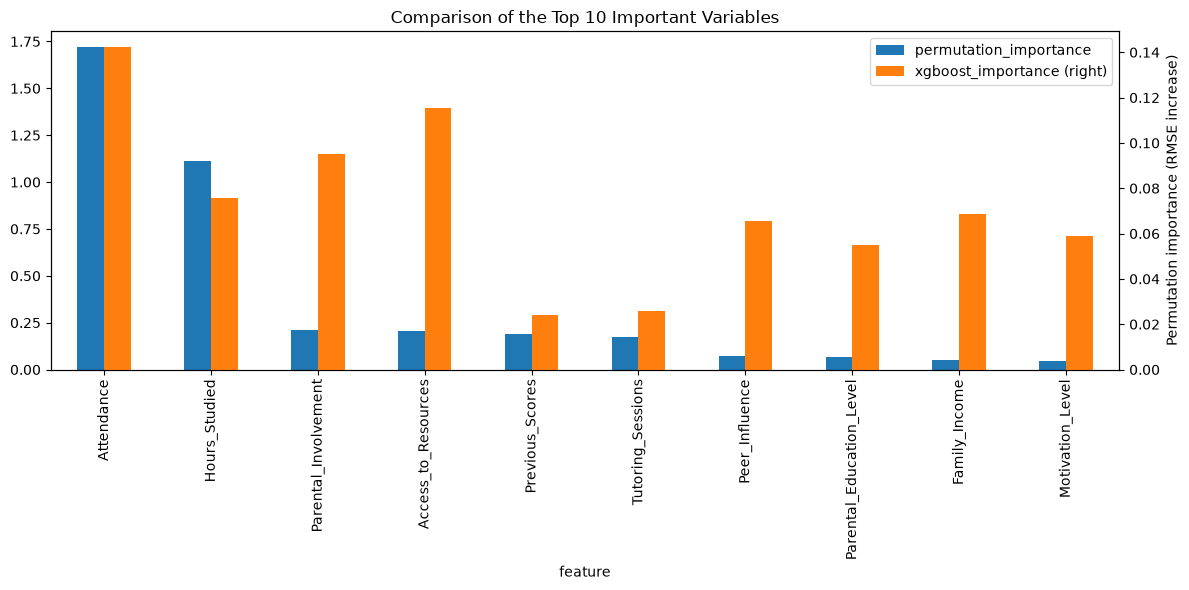

In [52]:
# Compare the top 10 features from permutation importance
comparison_plot = importance_comparison.head(10).set_index("feature")

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    secondary_y="xgboost_importance"
)
plt.title("Comparison of the Top 10 Important Variables")
plt.xlabel("Feature")
plt.ylabel("Permutation importance (RMSE increase)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 5. Interpretation and conclusions

After running all cells, use the two importance rankings and the relationship plots to identify the variables most useful for predicting insurance charges.

- A high **permutation importance** means the model's test-set error increases substantially when that column is shuffled.
- A high **XGBoost importance** means the fitted trees relied more heavily on that feature according to XGBoost's internal importance measure.
- If a feature ranks highly in both methods, that is stronger evidence that it is useful to this model.
- The relationship plots help explore how charges vary across values or categories, but they do not establish causation.

**Important:** Feature importance is specific to this dataset, model, and train/test split. Correlated variables can share or mask importance. These results describe predictive associations; they do not prove that a variable causes insurance charges to change. The analysis is educational and should not be treated as individual insurance or medical advice.
